In [1]:
# Importing Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\aarni\anaconda3\envs\python_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


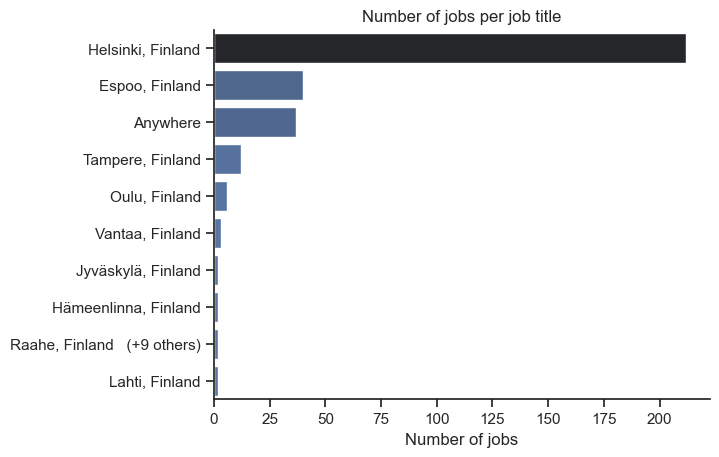

In [16]:
df_DA_FI=df[(df['job_country'] == 'Finland') & (df['job_title_short'] == 'Data Analyst')]
df_plot = df_DA_FI['job_location'].value_counts().drop('Finland', errors='ignore').head(10).to_frame()
sns.set_theme(style='ticks')
sns.barplot(data=df_plot, x='count', y='job_location', hue='count', palette='dark:b_r', legend=False)
sns.despine()
plt.title('Number of jobs per job title')
plt.xlabel('Number of jobs')
plt.ylabel('')
plt.show()

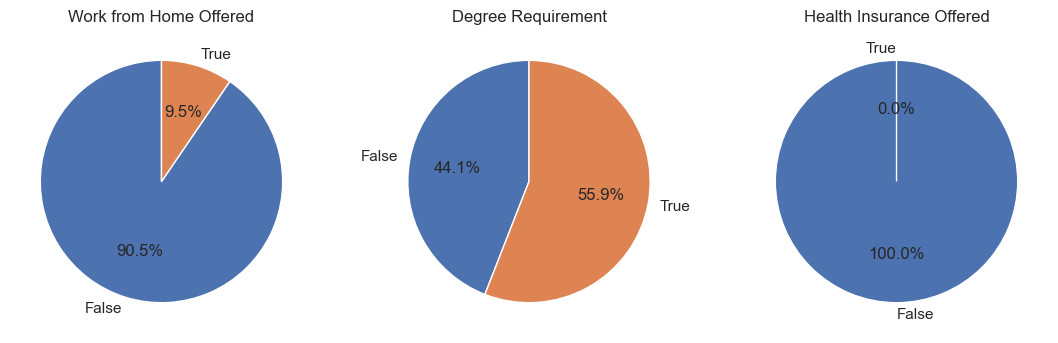

In [ ]:
dict_column = {
    'job_work_from_home': 'Work from Home Offered',
    'job_no_degree_mention': 'Degree Requirement',
    'job_health_insurance': 'Health Insurance Offered'
}

fig, ax = plt.subplots(1, 3, figsize=(11, 3.5))

for i, (column, title) in enumerate(dict_column.items()):
    
    counts = df_DA_FI[column].value_counts().reindex([False, True], fill_value=0)
    
    ax[i].pie(counts, labels=['False', 'True'], autopct='%1.1f%%', startangle=90)
    ax[i].set_title(title)

plt.tight_layout()
plt.show()

# In US Degree requirement True = 28%

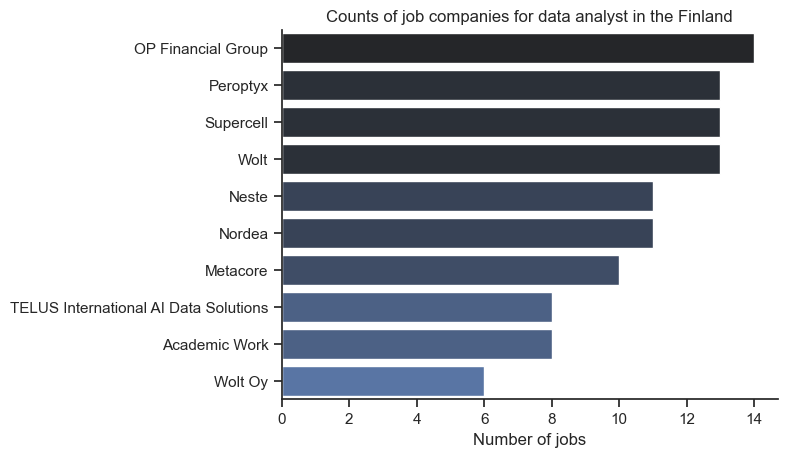

In [29]:


df_DA_FI = df[(df['job_country'] == 'Finland') & (df['job_title_short'] == 'Data Analyst')]
df_plot = df_DA_FI['company_name'].drop('Finland', errors='ignore').value_counts().head(10).to_frame()
sns.set_theme(style='ticks')
sns.barplot(data=df_plot, x='count', y='company_name', hue='count', palette='dark:b_r', legend=False)
sns.despine()
plt.title('Counts of job companies for data analyst in the Finland')
plt.xlabel('Number of jobs')
plt.ylabel('')
plt.show()